In [ ]:
import os
import json
import random
import shutil
import zipfile
from collections import Counter

import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# =====================================================================
# Step 1: Mount Google Drive (uncomment if not mounted yet)
# =====================================================================
# from google.colab import drive
# drive.mount('/content/drive')

# =====================================================================
# Step 2: Copy zip to local disk and extract (much faster than reading Drive)
# =====================================================================
ZIP_ON_DRIVE = "/content/drive/MyDrive/CSC490_data/d2c_v3.zip"
LOCAL_ZIP = "/content/d2c_v3.zip"
EXTRACT_TO = "/content"
DATA_ROOT = "/content/d2c_v2"          # top-level folder inside the zip

INCLUDE_BENIGN = True                  # False = experiment A, True = experiment B
DATASET_JSON = "master_dataset_with_benign.json" if INCLUDE_BENIGN else "master_dataset.json"

if not os.path.exists(os.path.join(DATA_ROOT, "master_dataset_with_benign.json")):
    print("Copying zip to local disk...")
    shutil.copy(ZIP_ON_DRIVE, LOCAL_ZIP)
    print("Extracting...")
    with zipfile.ZipFile(LOCAL_ZIP, "r") as z:
        z.extractall(EXTRACT_TO)
print("Data ready at", DATA_ROOT)

# =====================================================================
# Step 3: Label maps
# =====================================================================
FAMILY_MAP = {"typography": 0, "colour": 1, "appearance": 2, "shape": 3, "layout": 4}
OPERATOR_MAP = {
    "font_size": 0, "font_weight": 1, "line_height": 2, "letter_spacing": 3,
    "text_color": 4, "background_color": 5, "opacity": 6,
    "border_radius": 7, "border_width": 8,
    "padding": 9, "margin": 10, "position": 11, "width": 12,
}
IGNORE = -100  # class targets for negatives; use CrossEntropyLoss(ignore_index=-100)

TRAIN_RATIO = 0.85
SPLIT_SEED = 490


def make_grouped_split(root, train_ratio=TRAIN_RATIO, seed=SPLIT_SEED):
    """A page and ALL of its variants always land in the same set (grouped by parent_id)."""
    with open(os.path.join(root, DATASET_JSON), encoding="utf-8") as f:
        recs = json.load(f)
    print(f"loaded {DATASET_JSON}: {len(recs)} pairs")

    pages = sorted({r["parent_id"] for r in recs})
    random.Random(seed).shuffle(pages)
    n_train = int(round(train_ratio * len(pages)))
    train_pages = set(pages[:n_train])

    train_recs = [r for r in recs if r["parent_id"] in train_pages]
    val_recs = [r for r in recs if r["parent_id"] not in train_pages]

    overlap = {r["parent_id"] for r in train_recs} & {r["parent_id"] for r in val_recs}
    assert not overlap, f"leakage: {len(overlap)} pages in both splits"

    for name, rs in [("train", train_recs), ("val", val_recs)]:
        n_pages = len({r["parent_id"] for r in rs})
        print(f"[{name}] {n_pages} pages | {len(rs)} pairs | labels: {dict(Counter(r['label'] for r in rs))}")
    return train_recs, val_recs


# =====================================================================
# Step 4: Dataset
# =====================================================================
class PairedUIRegressionDataset(Dataset):
    """
    Returns (reference, candidate) image pairs.

    mode="tile": crop the SAME window from both images at native resolution.
        - regression: window placed around the mutated element (bbox), with random jitter
        - negatives : random window inside the height both images share
    mode="full": resize the whole page to full_size (small changes may disappear).
    """

    def __init__(self, records, root, mode="tile", tile=512, full_size=(448, 448),
                 jitter=True, transform=None):
        self.records = records
        self.root = root
        self.mode = mode
        self.tile = tile
        self.full_size = full_size
        self.jitter = jitter
        self.transform = transform or transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.records)

    @staticmethod
    def _pad_to(img, W, H):
        """Pad with white so both images share the same canvas."""
        if img.size == (W, H):
            return img
        canvas = Image.new("RGB", (W, H), "white")
        canvas.paste(img, (0, 0))
        return canvas

    def _target_box(self, r):
        """Union of bbox before/after, i.e. where the change lives."""
        b0, b1 = r.get("bbox_before"), r.get("bbox_after")
        if not b0 or not b1:
            return None
        x0 = min(b0[0], b1[0]); y0 = min(b0[1], b1[1])
        x1 = max(b0[0] + b0[2], b1[0] + b1[2]); y1 = max(b0[1] + b0[3], b1[1] + b1[3])
        return x0, y0, x1, y1

    def _choose_window(self, r, W, H, H_common):
        T = self.tile
        box = self._target_box(r) if r["label"] == "regression" else None
        if box is None:
            # negatives: stay inside the height both images share (never crop the white padding)
            x = random.randint(0, max(0, W - T))
            y = random.randint(0, max(0, min(H, H_common) - T))
            return x, y
        cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
        if self.jitter:  # so the change is not always dead-centre
            cx += random.uniform(-T / 4, T / 4)
            cy += random.uniform(-T / 4, T / 4)
        x = int(min(max(0, cx - T / 2), max(0, W - T)))
        y = int(min(max(0, cy - T / 2), max(0, H - T)))
        return x, y

    def __getitem__(self, idx):
        r = self.records[idx]
        ref = Image.open(os.path.join(self.root, r["reference_path"])).convert("RGB")
        cand = Image.open(os.path.join(self.root, r["candidate_path"])).convert("RGB")

        H_common = min(ref.height, cand.height)   # measured BEFORE padding
        W, H = max(ref.width, cand.width), max(ref.height, cand.height)
        ref, cand = self._pad_to(ref, W, H), self._pad_to(cand, W, H)

        if self.mode == "tile":
            T = self.tile
            if W < T or H < T:  # tiny page: pad up to one tile
                W2, H2 = max(W, T), max(H, T)
                ref, cand = self._pad_to(ref, W2, H2), self._pad_to(cand, W2, H2)
                W, H = W2, H2
            x, y = self._choose_window(r, W, H, H_common)
            ref = ref.crop((x, y, x + T, y + T))
            cand = cand.crop((x, y, x + T, y + T))
        else:
            ref = ref.resize(self.full_size, Image.BILINEAR)
            cand = cand.resize(self.full_size, Image.BILINEAR)

        is_reg = r["label"] == "regression"
        return {
            "img_ref": self.transform(ref),
            "img_cand": self.transform(cand),
            "is_regression": torch.tensor(1.0 if is_reg else 0.0),
            "family": torch.tensor(FAMILY_MAP[r["family"]] if is_reg else IGNORE),
            "operator": torch.tensor(OPERATOR_MAP[r["operator"]] if is_reg else IGNORE),
            "sample_id": r["sample_id"],
        }


# =====================================================================
# Step 5: Loaders + class balance
# =====================================================================
train_recs, val_recs = make_grouped_split(DATA_ROOT)

train_ds = PairedUIRegressionDataset(train_recs, DATA_ROOT, mode="tile", jitter=True)
val_ds = PairedUIRegressionDataset(val_recs, DATA_ROOT, mode="tile", jitter=False)

n_pos = sum(r["label"] == "regression" for r in train_recs)
n_neg = len(train_recs) - n_pos
pos_weight = torch.tensor(n_neg / max(1, n_pos))
print(f"train pos={n_pos} neg={n_neg} -> pos_weight={pos_weight.item():.3f}")

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

# =====================================================================
# Step 6: Sanity check
# =====================================================================
batch = next(iter(train_loader))
print("\n--- Pipeline Verification ---")
print("ref  batch:", tuple(batch["img_ref"].shape))
print("cand batch:", tuple(batch["img_cand"].shape))
print("is_regression:", batch["is_regression"].tolist())
print("family:", batch["family"].tolist())
print("operator:", batch["operator"].tolist())

Copying zip to local disk...
Extracting...
Data ready at /content/d2c_v2
loaded master_dataset_with_benign.json: 7271 pairs
[train] 411 pages | 6188 pairs | labels: {'no_change': 411, 'regression': 4955, 'benign': 822}
[val] 73 pages | 1083 pairs | labels: {'no_change': 73, 'regression': 864, 'benign': 146}
train pos=4955 neg=1233 -> pos_weight=0.249

--- Pipeline Verification ---
ref  batch: (16, 3, 512, 512)
cand batch: (16, 3, 512, 512)
is_regression: [1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 1.0, 0.0]
family: [1, -100, -100, 1, -100, 4, 4, 1, -100, -100, 3, 0, -100, 3, 4, -100]
operator: [4, -100, -100, 4, -100, 11, 11, 4, -100, -100, 7, 1, -100, 8, 9, -100]


In [ ]:
!pip -q install -U timm

In [ ]:
import timm, torch

enc = timm.create_model("sam2_hiera_tiny.fb_r896", pretrained=True,
                        features_only=True, out_indices=(-1,))
print("output channels:", enc.feature_info.channels())
with torch.no_grad():
    out = enc(torch.randn(1, 3, 512, 512))
print("feature map shape:", tuple(out[-1].shape))

model.safetensors: reconstructing file:   0%|          |  0.00B /  107MB            

model.safetensors: downloading bytes:           |  0.00B            

output channels: [768]
feature map shape: (1, 768, 16, 16)


In [ ]:
"""
Basic SAM2 (Hiera image encoder) training, run AFTER the dataloader cell:
1) train a binary classifier: regression vs. not regression
2) print the confusion matrix on the validation set
Same Siamese design as the ConvNeXt model; only the backbone is different.
"""
import os
import time
import random

import numpy as np
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix

# ---------------- config ----------------
EPOCHS = 8
BATCH = 8                      # drop to 4 if CUDA out of memory
LR_BACKBONE = 2e-5
LR_HEAD = 3e-4
WARMUP_STEPS = 300
SEED = 490
CKPT = f"/content/drive/MyDrive/CSC490_data/checkpoints/basic_sam2_{'B' if INCLUDE_BENIGN else 'A'}.pt"
os.makedirs(os.path.dirname(CKPT), exist_ok=True)

torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
device = "cuda"
assert torch.cuda.is_available(), "Switch the Colab runtime to a GPU before training."

# ---------------- data ----------------
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, drop_last=True,
                          num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=0)

n_pos = sum(r["label"] == "regression" for r in train_recs)
n_neg = len(train_recs) - n_pos
pos_weight = torch.tensor([n_neg / n_pos], device=device)   # regression is the majority class

# ---------------- model ----------------
class SiameseSAM2(nn.Module):
    """Shared SAM2 Hiera encoder on both images; fuse [ref, cand, |diff|] features; one binary output."""
    def __init__(self):
        super().__init__()
        self.trunk = timm.create_model("sam2_hiera_tiny.fb_r896", pretrained=True,
                                       features_only=True, out_indices=(-1,))
        ch = self.trunk.feature_info.channels()[-1]
        self.fuse = nn.Sequential(
            nn.Conv2d(ch * 3, 256, 1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
        )
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 1))

    def forward(self, a, b):
        fa, fb = self.trunk(a)[-1], self.trunk(b)[-1]
        x = self.fuse(torch.cat([fa, fb, (fa - fb).abs()], dim=1))
        x = torch.cat([F.adaptive_avg_pool2d(x, 1), F.adaptive_max_pool2d(x, 1)], dim=1).flatten(1)
        return self.head(x).squeeze(1)

model = SiameseSAM2().to(device)
print(f"params: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")
opt = torch.optim.AdamW([
    {"params": model.trunk.parameters(), "lr": LR_BACKBONE},
    {"params": list(model.fuse.parameters()) + list(model.head.parameters()), "lr": LR_HEAD},
], weight_decay=1e-4)
total_steps = EPOCHS * len(train_loader)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: min(1.0, (s + 1) / WARMUP_STEPS) * 0.5 * (1 + np.cos(np.pi * min(1.0, s / total_steps))))
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
scaler = torch.amp.GradScaler("cuda")

# ---------------- 1) train ----------------
for ep in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); tot, n = 0.0, 0
    for i, b in enumerate(train_loader):
        a = b["img_ref"].to(device, non_blocking=True)
        c = b["img_cand"].to(device, non_blocking=True)
        y = b["is_regression"].to(device, non_blocking=True)
        with torch.autocast("cuda"):
            loss = loss_fn(model(a, c).float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item() * len(y); n += len(y)
        if i % 100 == 0:
            print(f"  ep{ep} it{i}/{len(train_loader)} loss {loss.item():.3f}")
    print(f"epoch {ep}: train_loss {tot/n:.3f} | {time.time()-t0:.0f}s")

torch.save(model.state_dict(), CKPT)
print("saved ->", CKPT)

# ---------------- 2) confusion matrix on validation ----------------
model.eval()
random.seed(0)  # fixed random tiles for the negatives
ys, preds = [], []
with torch.no_grad():
    for b in val_loader:
        with torch.autocast("cuda"):
            logit = model(b["img_ref"].to(device), b["img_cand"].to(device))
        preds += (torch.sigmoid(logit.float()) >= 0.5).int().cpu().tolist()
        ys += b["is_regression"].int().tolist()

cm = confusion_matrix(ys, preds, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print("\nConfusion matrix (validation, threshold 0.5)")
print("                 pred: not reg   pred: regression")
print(f"true: not reg    {tn:>13}   {fp:>16}")
print(f"true: regression {fn:>13}   {tp:>16}")
print(f"\naccuracy {(tp + tn) / cm.sum():.3f} | precision {tp / max(1, tp + fp):.3f} | "
      f"recall {tp / max(1, tp + fn):.3f} | false-positive rate {fp / max(1, fp + tn):.3f}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  107MB            

model.safetensors: downloading bytes:           |  0.00B            

params: 28.0M


/tmp/ipykernel_685/1303098946.py:84: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


  ep1 it0/773 loss 0.338
  ep1 it100/773 loss 0.278
  ep1 it200/773 loss 0.425
  ep1 it300/773 loss 0.117
  ep1 it400/773 loss 0.051
  ep1 it500/773 loss 0.179
  ep1 it600/773 loss 0.043
  ep1 it700/773 loss 0.047
epoch 1: train_loss 0.159 | 352s
  ep2 it0/773 loss 0.023
  ep2 it100/773 loss 0.031
  ep2 it200/773 loss 0.078
  ep2 it300/773 loss 0.055
  ep2 it400/773 loss 0.052
  ep2 it500/773 loss 0.052
  ep2 it600/773 loss 0.070
  ep2 it700/773 loss 0.135
epoch 2: train_loss 0.091 | 350s
  ep3 it0/773 loss 0.048
  ep3 it100/773 loss 0.127
  ep3 it200/773 loss 0.026
  ep3 it300/773 loss 0.082
  ep3 it400/773 loss 0.137
  ep3 it500/773 loss 0.035
  ep3 it600/773 loss 0.013
  ep3 it700/773 loss 0.026
epoch 3: train_loss 0.069 | 352s
  ep4 it0/773 loss 0.130
  ep4 it100/773 loss 0.004
  ep4 it200/773 loss 0.018
  ep4 it300/773 loss 0.076
  ep4 it400/773 loss 0.068
  ep4 it500/773 loss 0.012
  ep4 it600/773 loss 0.034
  ep4 it700/773 loss 0.046
epoch 4: train_loss 0.064 | 351s
  ep5 it0/77

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# SAM2 breakdown: false positives per negative type + recall per family (uses the model in memory)
import numpy as np

model.eval()
random.seed(0)  # same random tiles for negatives as the ConvNeXt evaluation
probs, ids = [], []
with torch.no_grad():
    for b in val_loader:
        with torch.autocast("cuda"):
            logit = model(b["img_ref"].to(device), b["img_cand"].to(device))
        probs += torch.sigmoid(logit.float()).cpu().tolist()
        ids += list(b["sample_id"])
pred = np.array(probs) >= 0.5
by_id = {r["sample_id"]: r for r in val_recs}
labels = np.array([by_id[s]["label"] for s in ids])

print(f"{'true type':<12}{'pred: not reg':>15}{'pred: regression':>18}")
for lab in ["no_change", "benign", "regression"]:
    m = labels == lab
    print(f"{lab:<12}{int((~pred[m]).sum()):>15}{int(pred[m].sum()):>18}")

print("\nrecall by family:")
for fam in FAMILY_MAP:
    idx = [i for i, s in enumerate(ids) if by_id[s]["label"] == "regression" and by_id[s]["family"] == fam]
    print(f"  {fam:<11} {pred[idx].mean():.2f}  (n={len(idx)})")

true type     pred: not reg  pred: regression
no_change                72                 1
benign                  139                 7
regression               58               806

recall by family:
  typography  0.94  (n=268)
  colour      0.98  (n=143)
  appearance  0.94  (n=70)
  shape       0.81  (n=99)
  layout      0.94  (n=284)


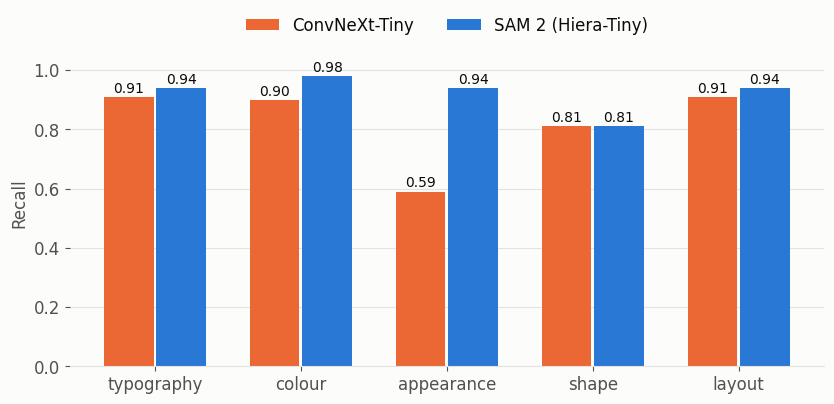

In [ ]:
# ConvNeXt vs SAM2: recall per mutation family (experiment B, same validation set)
import os
import numpy as np
import matplotlib.pyplot as plt

FIG_DIR = "/content/drive/MyDrive/CSC490_data/figures"
os.makedirs(FIG_DIR, exist_ok=True)
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.edgecolor": GRID, "font.size": 12})

fams = ["typography", "colour", "appearance", "shape", "layout"]
recall = {"ConvNeXt-Tiny": [0.91, 0.90, 0.59, 0.81, 0.91],
          "SAM 2 (Hiera-Tiny)": [0.94, 0.98, 0.94, 0.81, 0.94]}

x = np.arange(len(fams)); w = 0.36
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for k, (name, color) in enumerate(zip(recall, [ORANGE, BLUE])):
    bars = ax.bar(x + (k - 0.5) * w, recall[name], w - 0.02, color=color, label=name)
    for b_, v in zip(bars, recall[name]):
        ax.text(b_.get_x() + b_.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", color=INK, fontsize=10)
ax.set_xticks(x, fams); ax.set_ylim(0, 1.1); ax.set_ylabel("Recall")
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.12))
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "convnext_vs_sam2_recall_by_family.png"), dpi=200)
plt.show()